# 固定营销名额下的客户策略评价

**决策问题：**只能触达约 20% 的候选客户时，按预测增量选择客户，是否比按购买倾向或传统客户价值选择更有效？

比较 Random、RFM、Response、Response_p1 和 Uplift 五种策略。主指标是相对完全不触达，每千名候选客户的新增购买人数；分母是全体候选客户。同一批客户上的策略差异按配对方式计算。

**结果来源：**本次运行的策略价值、配对差异和区间由下方代码计算，保存至 `reports/tables/`。README 展示的是历史固定划分的结果；新划分或合成数据请以各自输出为准。

**分析历史：**原主要比较为 Uplift − Response。Response_p1、分组校准及 DR/IPW 核对为后续探索分析。测试集未参与模型拟合，但其结果此前已经查看；整理及重算不能构成新的未查看测试集检验。

**证据边界：**处理概率 `e=0.5` 仍为待核实假设。验证集 Uplift − Response_p1 的 DR 区间不含零，IPW 区间包含零，不能称为两种方法均显著确认优势。区间条件于已训练模型，使用独立客户近似，未作多重比较校正。20% 为容量设定，不是已确认的最优预算。

2026-10-25 完善复现流程；使用 02 生成的模型重新计算既有评价。模型、主比较和触达比例不变，重算不产生新的独立测试证据。研究设计、来源及复现状态见 [README](README.md) 与 [研究设计说明](docs/research_design.md)。


## 1. 读取验证数据与预测


In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

train_df = duckdb.sql("""
    SELECT * FROM read_parquet('data/processed/train.parquet')
""").df()

valid_df = duckdb.sql("""
    SELECT * FROM read_parquet('data/processed/validation.parquet')
""").df()

scores = duckdb.sql("""
    SELECT * FROM read_parquet(
        'data/processed/validation_scores.parquet'
    )
""").df()

score_columns = ["response_score", "p0", "p1", "uplift_score"]

evaluation = valid_df.merge(
    scores[["client_id"] + score_columns],
    on="client_id",
    how="left",
    validate="one_to_one"
).reset_index(drop=True)

assert len(evaluation) == len(valid_df)
assert evaluation[score_columns].notna().all().all()

print("评价客户数：", len(evaluation))

评价客户数： 40008


## 2. 定义统一评价规则

RFM 的五分位阈值仅从训练集计算：最近购买越近、交易越频繁、消费越高，得分越高；三项等权。所有策略使用相同名额，同分时按客户 ID 排序。随机基线表示随机选择相同人数的期望收益。


In [2]:
import json
import joblib
from IPython.display import display, Markdown

rfm_thresholds = {
    column: train_df[column].quantile([0.2, 0.4, 0.6, 0.8]).tolist()
    for column in ["recency_days", "txn_count_history", "spend_history"]
}

policy_config = {
    "budget_share": 0.20,
    "propensity": 0.5,
    "propensity_status": "assumed_unverified",
    "rfm_thresholds": rfm_thresholds,
    "ranking_columns": {
        "RFM": "rfm_score",
        "Response": "response_score",
        "Response_p1": "p1",
        "Uplift": "uplift_score"
    },
    "comparison_baselines": ["Response", "Response_p1", "Random", "RFM"],
    "primary_comparison": "Uplift - Response",
    "added_exploratory_comparisons": ["Uplift - Response_p1"],
    "test_set_status": "previously_examined",
    "tie_breaker": "client_id_ascending"
}

strategy_order = ["Random"] + list(policy_config["ranking_columns"])
Path("models").mkdir(parents=True, exist_ok=True)
Path("reports/tables").mkdir(parents=True, exist_ok=True)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
with open("models/policy_config.json", "w", encoding="utf-8") as f:
    json.dump(policy_config, f, ensure_ascii=False, indent=2)

print("触达比例：", policy_config["budget_share"])
print("策略：", ", ".join(strategy_order))


触达比例： 0.2
策略： Random, RFM, Response, Response_p1, Uplift


### 统一的客户选择与评价函数

DR 分数结合预测概率与实际结果；IPW 仅根据处理概率对实际结果加权。两者使用同一客户选择规则。DR 分数不是个人真实因果效应标签。


In [3]:
# 统一评价实现保留原公式、名额、RFM 阈值及配对差异；增加输入校验。
from src.causal_robustness import build_policies, evaluate_policies

def evaluate_fixed_policies(data, config, method="DR"):
    return evaluate_policies(data, config, method=method)


## 3. 验证集：五策略收益与配对差异


In [4]:
validation_policy_results, validation_comparison_results = evaluate_fixed_policies(
    evaluation, policy_config
)
display(validation_policy_results.round(2))
display(validation_comparison_results.round(2))


,strategy,contacts_per_1000,gain_per_1000,ci_low,ci_high
0,Random,200.01,6.38,4.70,8.07
1,RFM,200.01,2.81,0.23,5.39
2,Response,200.01,2.78,0.41,5.15
3,Response_p1,200.01,3.82,1.45,6.20
4,Uplift,200.01,10.73,6.58,14.89


,comparison,extra_gain_per_1000,ci_low,ci_high
0,Uplift - Response,7.96,3.19,12.73
1,Uplift - Response_p1,6.91,2.15,11.67
2,Uplift - Random,4.35,0.71,7.99
3,Uplift - RFM,7.92,3.10,12.75


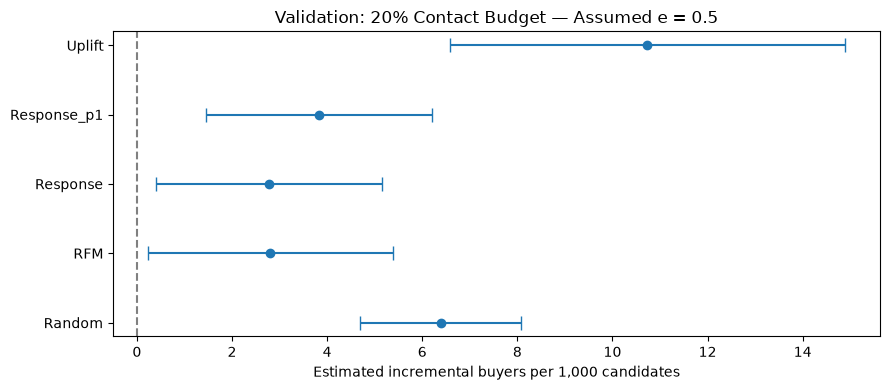

In [5]:
plot_data = validation_policy_results.set_index("strategy").loc[
    strategy_order
]

fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(plot_data))

ax.errorbar(
    plot_data["gain_per_1000"],
    positions,
    xerr=np.vstack([
        plot_data["gain_per_1000"] - plot_data["ci_low"],
        plot_data["ci_high"] - plot_data["gain_per_1000"]
    ]),
    fmt="o",
    capsize=5
)

ax.set_yticks(positions, labels=plot_data.index)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("Estimated incremental buyers per 1,000 candidates")
ax.set_title("Validation: 20% Contact Budget — Assumed e = 0.5")

plt.tight_layout()
plt.show()

Path("reports/tables").mkdir(parents=True, exist_ok=True)
Path("reports/figures").mkdir(parents=True, exist_ok=True)

validation_policy_results.to_csv(
    "reports/tables/validation_policy_results.csv",
    index=False
)

validation_comparison_results.to_csv(
    "reports/tables/validation_policy_comparisons.csv",
    index=False
)

fig.savefig(
    "reports/figures/validation_policy_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

In [6]:
uplift_row = validation_policy_results.set_index("strategy").loc["Uplift"]
p1_difference = validation_comparison_results.set_index("comparison").loc["Uplift - Response_p1"]
display(Markdown(f"""
### 验证集结果说明

Uplift 相对完全不触达，每千名候选客户估计增加 **{uplift_row['gain_per_1000']:.2f}** 名购买客户，近似 95% CI 为 **[{uplift_row['ci_low']:.2f}, {uplift_row['ci_high']:.2f}]**。

新增的 Uplift − Response_p1 配对差异为 **{p1_difference['extra_gain_per_1000']:.2f}** 人／千人，近似 95% CI 为 **[{p1_difference['ci_low']:.2f}, {p1_difference['ci_high']:.2f}]**。

策略优劣应根据配对差异及其区间判断，而不是根据两个策略各自区间是否重叠。原主要比较仍为 Uplift − Response，新增的 Response_p1 比较属于探索分析。
"""))



### 验证集结果说明

Uplift 相对完全不触达，每千名候选客户估计增加 **10.73** 名购买客户，近似 95% CI 为 **[6.58, 14.89]**。

新增的 Uplift − Response_p1 配对差异为 **6.91** 人／千人，近似 95% CI 为 **[2.15, 11.67]**。

策略优劣应根据配对差异及其区间判断，而不是根据两个策略各自区间是否重叠。原主要比较仍为 Uplift − Response，新增的 Response_p1 比较属于探索分析。


## 4. 验证集：DR 与 IPW 交叉核对

保持模型、客户和触达比例不变。两种方法的点估计不必一致；IPW 区间跨零表示证据不足，不能直接解释为没有策略差异。


In [7]:
gain_frames = []
comparison_frames = []
for method in ["DR", "IPW"]:
    if method == "DR":
        gains = validation_policy_results.copy()
        comparisons = validation_comparison_results.copy()
    else:
        gains, comparisons = evaluate_fixed_policies(evaluation, policy_config, method=method)
    gains = gains.rename(columns={"gain_per_1000": "estimate_per_1000"})
    comparisons = comparisons.rename(columns={"extra_gain_per_1000": "estimate_per_1000"})
    gains["method"] = method
    comparisons["method"] = method
    gain_frames.append(gains[["strategy", "method", "estimate_per_1000", "ci_low", "ci_high"]])
    comparison_frames.append(comparisons[["comparison", "method", "estimate_per_1000", "ci_low", "ci_high"]])

estimator_gain_results = pd.concat(gain_frames, ignore_index=True)
estimator_comparison_results = pd.concat(comparison_frames, ignore_index=True)
display(estimator_gain_results.sort_values(["strategy", "method"]).round(2))
display(estimator_comparison_results.sort_values(["comparison", "method"]).round(2))
estimator_gain_results.to_csv("reports/tables/validation_dr_ipw_gains.csv", index=False)
estimator_comparison_results.to_csv("reports/tables/validation_dr_ipw_comparisons.csv", index=False)


,strategy,method,estimate_per_1000,ci_low,ci_high
1,RFM,DR,2.81,0.23,5.39
6,RFM,IPW,2.40,-5.91,10.71
0,Random,DR,6.38,4.70,8.07
5,Random,IPW,6.55,3.46,9.64
2,Response,DR,2.78,0.41,5.15
7,Response,IPW,1.45,-6.95,9.85
3,Response_p1,DR,3.82,1.45,6.20
8,Response_p1,IPW,2.75,-5.65,11.15
4,Uplift,DR,10.73,6.58,14.89
9,Uplift,IPW,7.90,1.70,14.10


,comparison,method,estimate_per_1000,ci_low,ci_high
3,Uplift - RFM,DR,7.92,3.10,12.75
7,Uplift - RFM,IPW,5.50,-4.75,15.75
2,Uplift - Random,DR,4.35,0.71,7.99
6,Uplift - Random,IPW,1.35,-4.36,7.06
0,Uplift - Response,DR,7.96,3.19,12.73
4,Uplift - Response,IPW,6.45,-3.93,16.82
1,Uplift - Response_p1,DR,6.91,2.15,11.67
5,Uplift - Response_p1,IPW,5.15,-5.19,15.49


In [8]:
gain_lookup = estimator_gain_results.set_index(["strategy", "method"])
comparison_lookup = estimator_comparison_results.set_index(["comparison", "method"])
summary_lines = ["### DR / IPW 核对结果", "", "Uplift 相对完全不触达："]
for method in ["DR", "IPW"]:
    row = gain_lookup.loc[("Uplift", method)]
    summary_lines.append(f"- {method}：{row['estimate_per_1000']:.2f} 人／千人，近似 95% CI [{row['ci_low']:.2f}, {row['ci_high']:.2f}]。")
summary_lines += ["", "Uplift 相对 Response_p1："]
for method in ["DR", "IPW"]:
    row = comparison_lookup.loc[("Uplift - Response_p1", method)]
    summary_lines.append(f"- {method}：{row['estimate_per_1000']:.2f} 人／千人，近似 95% CI [{row['ci_low']:.2f}, {row['ci_high']:.2f}]。")
dr_diff = comparison_lookup.loc[("Uplift - Response_p1", "DR")]
ipw_diff = comparison_lookup.loc[("Uplift - Response_p1", "IPW")]
if dr_diff['ci_low'] > 0 and ipw_diff['ci_low'] <= 0 <= ipw_diff['ci_high']:
    summary_lines += ["", "对于这一新增比较，优于基线的统计证据主要来自 DR；IPW 区间包含零，不能写成两种方法均显著确认优势。"]
summary_lines += ["", "本检查未直接检验两种估计值之间的差异。两种方法共享处理概率和识别假设，结果一致也不能验证这些假设。本节不用于调整模型或触达名额。"]
display(Markdown("\n".join(summary_lines)))


### DR / IPW 核对结果

Uplift 相对完全不触达：
- DR：10.73 人／千人，近似 95% CI [6.58, 14.89]。
- IPW：7.90 人／千人，近似 95% CI [1.70, 14.10]。

Uplift 相对 Response_p1：
- DR：6.91 人／千人，近似 95% CI [2.15, 11.67]。
- IPW：5.15 人／千人，近似 95% CI [-5.19, 15.49]。

对于这一新增比较，优于基线的统计证据主要来自 DR；IPW 区间包含零，不能写成两种方法均显著确认优势。

本检查未直接检验两种估计值之间的差异。两种方法共享处理概率和识别假设，结果一致也不能验证这些假设。本节不用于调整模型或触达名额。

## 5. 验证集预算曲线

沿用原有 0%–100% 的预算曲线分析，五种策略使用同一评价函数。不同预算仅用于探索；主要预算仍为 20%。


In [9]:
curve_rows = []

for budget in np.linspace(0, 1, 21):
    curve_config = {
        **policy_config,
        "budget_share": float(budget)
    }

    budget_results, _ = evaluate_fixed_policies(
        evaluation,  # 前面关联好的验证集
        curve_config
    )

    budget_results["budget_share"] = float(budget)
    curve_rows.append(budget_results)

validation_budget_curve = pd.concat(
    curve_rows,
    ignore_index=True
)

validation_budget_curve.to_csv(
    "reports/tables/validation_budget_curve.csv",
    index=False
)

In [10]:
# 预算端点一致性检查
zero_budget = validation_budget_curve.loc[validation_budget_curve["budget_share"].eq(0)]
full_budget = validation_budget_curve.loc[validation_budget_curve["budget_share"].eq(1)]
assert np.allclose(zero_budget["gain_per_1000"], 0)
assert np.allclose(full_budget["gain_per_1000"], full_budget["gain_per_1000"].iloc[0])
print("预算端点检查通过：0% 时收益为零，100% 时五种策略收益一致。")


预算端点检查通过：0% 时收益为零，100% 时五种策略收益一致。


## 6. 已有测试集上的固定方案评价

使用已保存模型进行预测，不在测试集拟合或调参。本测试集此前已查看；下面是整理版的结果重算，新增 Response_p1 比较属于探索性补充，不宣称是新的独立确认。


In [11]:
with open(
    "models/model_config.json", encoding="utf-8"
) as f:
    model_config = json.load(f)

response_model = joblib.load("models/response_model.joblib")
m0 = joblib.load("models/tlearner_m0.joblib")
m1 = joblib.load("models/tlearner_m1.joblib")

test_df = duckdb.sql("""
    SELECT * FROM read_parquet('data/processed/test.parquet')
""").df()

X_test = test_df[model_config["feature_columns"]]

test_evaluation = test_df.copy()

test_evaluation["response_score"] = (
    response_model.predict_proba(X_test)[:, 1]
)
test_evaluation["p0"] = m0.predict_proba(X_test)[:, 1]
test_evaluation["p1"] = m1.predict_proba(X_test)[:, 1]
test_evaluation["uplift_score"] = (
    test_evaluation["p1"] - test_evaluation["p0"]
)

In [12]:
test_policy_results, test_comparison_results = (
    evaluate_fixed_policies(
        test_evaluation,
        policy_config
    )
)

display(test_policy_results.round(2))
display(test_comparison_results.round(2))

test_policy_results.to_csv(
    "reports/tables/test_policy_results.csv",
    index=False
)

test_comparison_results.to_csv(
    "reports/tables/test_policy_comparisons.csv",
    index=False
)

,strategy,contacts_per_1000,gain_per_1000,ci_low,ci_high
0,Random,200.01,5.20,3.52,6.89
1,RFM,200.01,1.55,-1.00,4.10
2,Response,200.01,2.57,0.27,4.88
3,Response_p1,200.01,3.04,0.73,5.35
4,Uplift,200.01,10.86,6.70,15.02


,comparison,extra_gain_per_1000,ci_low,ci_high
0,Uplift - Response,8.29,3.55,13.02
1,Uplift - Response_p1,7.82,3.09,12.55
2,Uplift - Random,5.65,2.02,9.29
3,Uplift - RFM,9.31,4.50,14.12


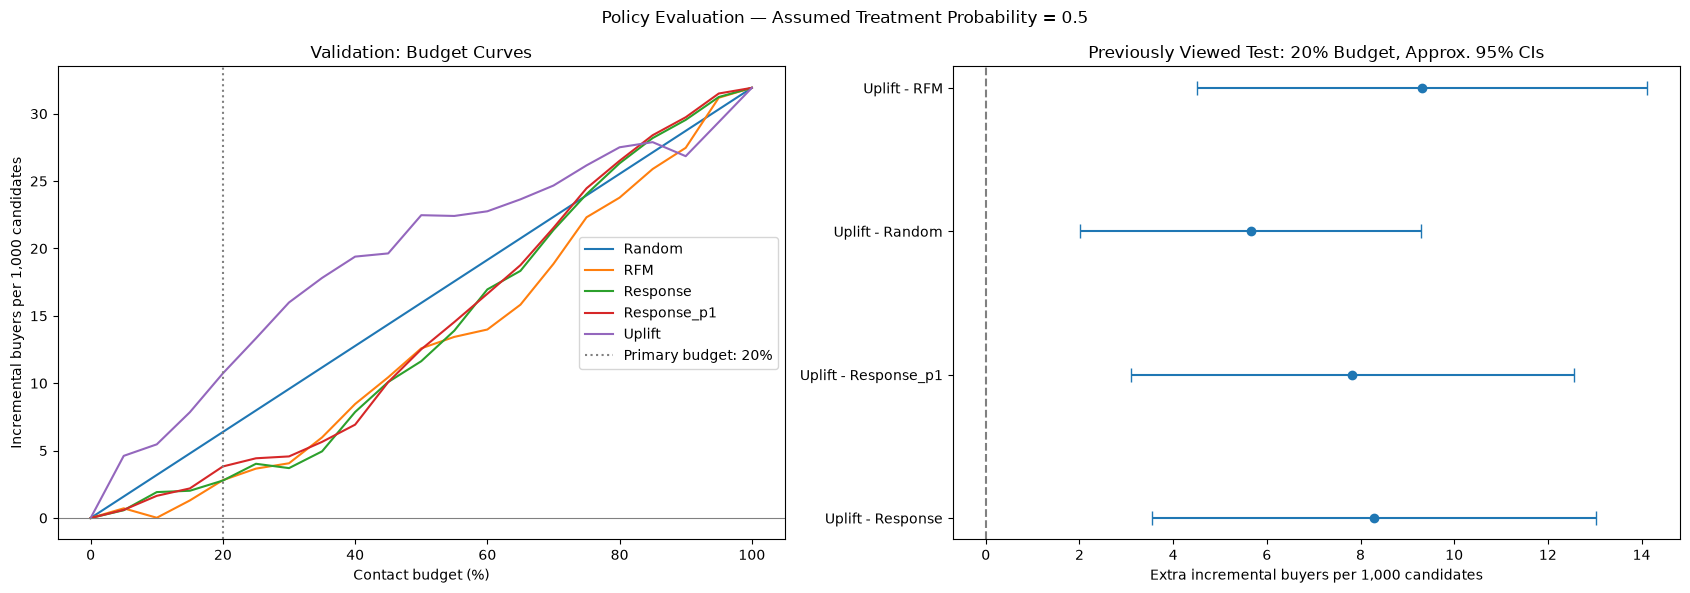

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# 左图：验证集上的不同预算
for strategy in strategy_order:
    subset = validation_budget_curve.loc[
        validation_budget_curve["strategy"].eq(strategy)
    ].sort_values("budget_share")

    axes[0].plot(
        subset["budget_share"] * 100,
        subset["gain_per_1000"],
        label=strategy
    )

axes[0].axvline(
    20,
    color="gray",
    linestyle=":",
    label="Primary budget: 20%"
)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_xlabel("Contact budget (%)")
axes[0].set_ylabel("Incremental buyers per 1,000 candidates")
axes[0].set_title("Validation: Budget Curves")
axes[0].legend()

# 右图：测试集上固定预算的配对差异
comparisons = test_comparison_results.copy()
positions = np.arange(len(comparisons))

axes[1].errorbar(
    comparisons["extra_gain_per_1000"],
    positions,
    xerr=np.vstack([
        comparisons["extra_gain_per_1000"]
        - comparisons["ci_low"],

        comparisons["ci_high"]
        - comparisons["extra_gain_per_1000"]
    ]),
    fmt="o",
    capsize=5
)

axes[1].set_yticks(
    positions,
    labels=comparisons["comparison"]
)
axes[1].axvline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Extra incremental buyers per 1,000 candidates")
axes[1].set_title("Previously Viewed Test: 20% Budget, Approx. 95% CIs")

fig.suptitle("Policy Evaluation — Assumed Treatment Probability = 0.5")
plt.tight_layout()

Path("reports/figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "reports/figures/policy_evaluation_summary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [14]:
test_lookup = test_comparison_results.set_index("comparison")
primary = test_lookup.loc[policy_config["primary_comparison"]]
added = test_lookup.loc["Uplift - Response_p1"]
test_uplift = test_policy_results.set_index("strategy").loc["Uplift"]

display(Markdown(f"""
## 7. 结论与限制

在约 20% 的触达比例下，本次使用 **{len(test_evaluation):,}** 名测试客户重新计算固定方案收益：

- Uplift 相对完全不触达：**{test_uplift['gain_per_1000']:.2f}** 人／千名候选客户，近似 95% CI **[{test_uplift['ci_low']:.2f}, {test_uplift['ci_high']:.2f}]**。
- 原主要比较 Uplift − Response：**{primary['extra_gain_per_1000']:.2f}** 人／千人，近似 95% CI **[{primary['ci_low']:.2f}, {primary['ci_high']:.2f}]**。
- 新增探索比较 Uplift − Response_p1：**{added['extra_gain_per_1000']:.2f}** 人／千人，近似 95% CI **[{added['ci_low']:.2f}, {added['ci_high']:.2f}]**。

以上是离线增量购买估计，不是利润或已验证的线上效果。原主要比较与新增探索比较应分别报告，不能把本次重算描述为新的未查看测试集检验。

验证集分组校准提示应区分排序价值与效果幅度的准确性；DR/IPW 核对需结合各自区间判断证据强度。处理概率 0.5、随机分配、真实处理时间和结果窗口仍待核实；特征平衡与统计区间不能替代因果识别依据。结论首先适用于本数据中的近期活跃客户。
"""))



## 7. 结论与限制

在约 20% 的触达比例下，本次使用 **40,008** 名测试客户重新计算固定方案收益：

- Uplift 相对完全不触达：**10.86** 人／千名候选客户，近似 95% CI **[6.70, 15.02]**。
- 原主要比较 Uplift − Response：**8.29** 人／千人，近似 95% CI **[3.55, 13.02]**。
- 新增探索比较 Uplift − Response_p1：**7.82** 人／千人，近似 95% CI **[3.09, 12.55]**。

以上是离线增量购买估计，不是利润或已验证的线上效果。原主要比较与新增探索比较应分别报告，不能把本次重算描述为新的未查看测试集检验。

验证集分组校准提示应区分排序价值与效果幅度的准确性；DR/IPW 核对需结合各自区间判断证据强度。处理概率 0.5、随机分配、真实处理时间和结果窗口仍待核实；特征平衡与统计区间不能替代因果识别依据。结论首先适用于本数据中的近期活跃客户。


## 新增稳健性分析的入口
本文件仍报告原固定方案。逐客户贡献的正态区间属于近似评价区间，不包含模型重新训练与模型选择的不确定性。
在 05 中补充验证集的客户 bootstrap，每次重新选取前 20%，保留重复抽中的客户副本，并计算同一重抽样本上的策略配对差异。该区间仍条件于已拟合模型，且不能修复混杂、既往测试集查看或多重比较问题。